In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

Load Dataset

In [5]:
DATA_PATH = "/Users/kingsice/Desktop/hotel_bookings.csv"   # change if the file lives elsewhere
  # change if the file lives elsewhere
FIG_DIR = "eda_figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

TARGET = "is_canceled"


def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()


In [6]:
#Load and first look
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.dtypes)
df.head()

Shape: (119390, 32)
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent         

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
#Data quality: missing values, duplicates, odd records
missing = (df.isna().mean() * 100).round(2)
print("Missing % (only columns with missing values):")
print(missing[missing > 0].sort_values(ascending=False))

print("\nExact duplicate rows:", df.duplicated().sum())

total_guests = df["adults"] + df["children"].fillna(0) + df["babies"]
total_nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
print("Bookings with zero guests:", (total_guests == 0).sum())
print("Bookings with zero nights:", (total_nights == 0).sum())
print("Bookings with ADR <= 0:", (df["adr"] <= 0).sum())
print("Bookings with ADR > 1000:", (df["adr"] > 1000).sum())

Missing % (only columns with missing values):
company    94.31
agent      13.69
country     0.41
dtype: float64

Exact duplicate rows: 31994
Bookings with zero guests: 180
Bookings with zero nights: 715
Bookings with ADR <= 0: 1960
Bookings with ADR > 1000: 1


In [8]:
#Leakage check: fields that reveal the outcome
# reservation_status maps directly onto the target, so it must NOT be a predictor.
print(pd.crosstab(df["reservation_status"], df[TARGET]))

LEAKY = ["reservation_status", "reservation_status_date"]

# Fields finalized after booking (or only at check-in). Discuss these in your
# report; for a booking-time model you would normally drop them.
POST_BOOKING = ["assigned_room_type", "booking_changes",
                "days_in_waiting_list", "required_car_parking_spaces"]

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


In [9]:
#Light cleaning for EDA (creates a copy; raw df is untouched)
d = df.drop(columns=LEAKY).copy()

d["children"] = d["children"].fillna(0)
d["country"] = d["country"].fillna("Unknown")
d["agent"] = d["agent"].fillna(0).astype(int).astype(str)      # 0 = no agent
d["company"] = d["company"].notna().astype(int)                # 1 = has company

# Engineered features
d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
d["total_guests"] = d["adults"] + d["children"] + d["babies"]
d["room_mismatch"] = (d["reserved_room_type"] != d["assigned_room_type"]).astype(int)

month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
d["arrival_date_month"] = pd.Categorical(d["arrival_date_month"],
                                         categories=month_order, ordered=True)

# Flag (don't delete yet) the odd records so the team can decide together
d["flag_odd"] = ((d["total_guests"] == 0) | (d["total_nights"] == 0)
                 | (d["adr"] <= 0) | (d["adr"] > 1000)).astype(int)
print("Flagged odd records:", d["flag_odd"].sum())

Flagged odd records: 1992


Overall cancellation rate: 37.0%


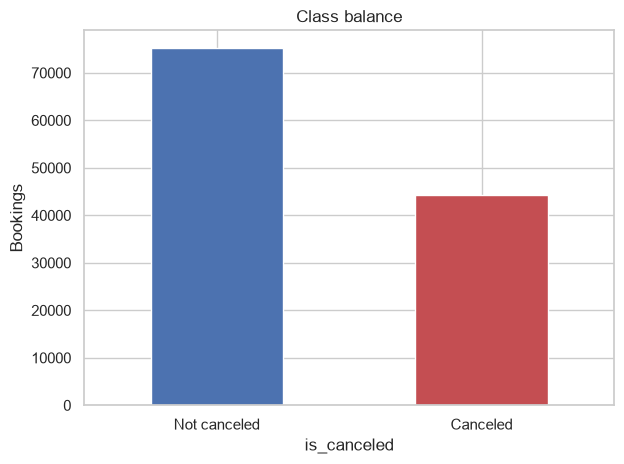

In [10]:
#Target overview
rate = d[TARGET].mean()
print(f"Overall cancellation rate: {rate:.1%}")

ax = d[TARGET].value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Not canceled", "Canceled"], rotation=0)
ax.set_ylabel("Bookings")
ax.set_title("Class balance")
save("01_class_balance")

In [11]:
#Helper: cancellation rate by a categorical column
def cancel_rate_by(col, data=d, min_count=0, top=None, figsize=(8, 4), name=None):
    g = (data.groupby(col, observed=True)[TARGET]
             .agg(rate="mean", n="size").reset_index())
    g = g[g["n"] >= min_count]
    if top:
        g = g.sort_values("n", ascending=False).head(top)
    g = g.sort_values("rate", ascending=False) if not hasattr(data[col], "cat") else g

    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(data=g, x=col, y="rate", ax=ax, color="#4C72B0")
    ax.axhline(rate, color="red", ls="--", label=f"Overall ({rate:.0%})")
    ax.set_ylabel("Cancellation rate")
    ax.set_title(f"Cancellation rate by {col}")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend()
    save(name or f"rate_by_{col}")
    return g

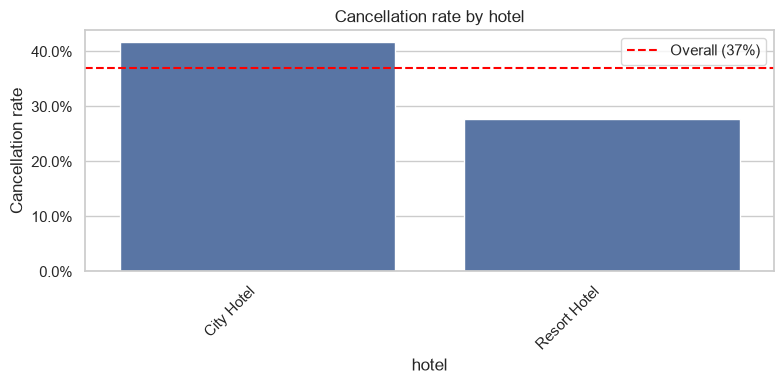

          hotel      rate      n
0    City Hotel  0.417270  79330
1  Resort Hotel  0.277634  40060 



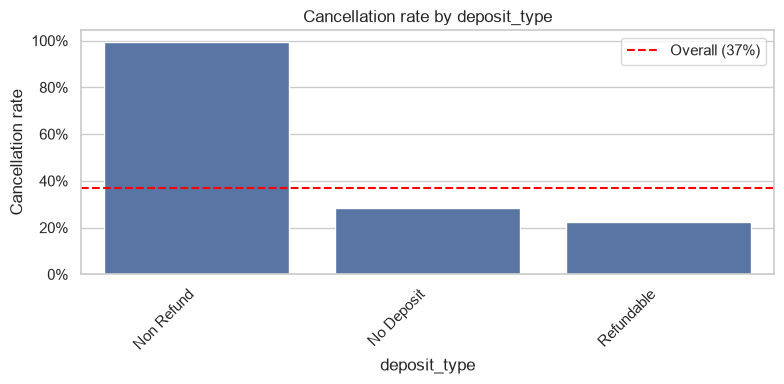

  deposit_type      rate       n
1   Non Refund  0.993624   14587
0   No Deposit  0.283770  104641
2   Refundable  0.222222     162 



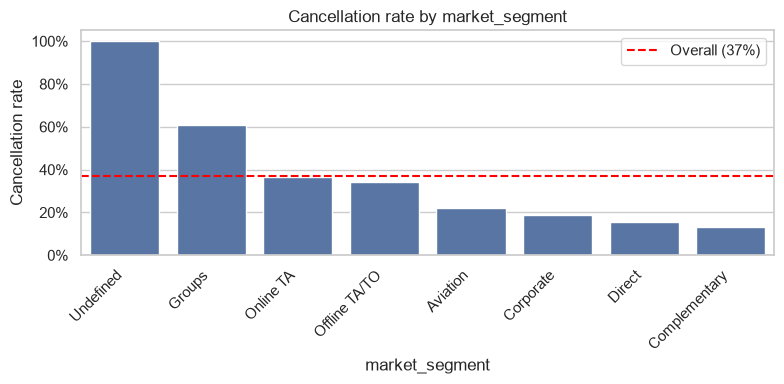

  market_segment      rate      n
7      Undefined  1.000000      2
4         Groups  0.610620  19811
6      Online TA  0.367211  56477
5  Offline TA/TO  0.343160  24219
0       Aviation  0.219409    237
2      Corporate  0.187347   5295
3         Direct  0.153419  12606
1  Complementary  0.130552    743 



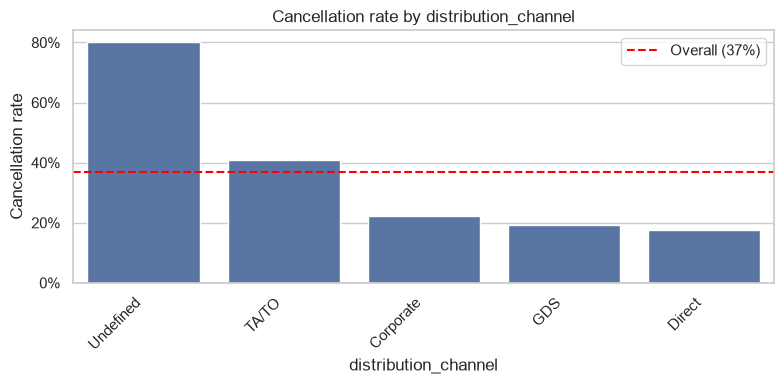

  distribution_channel      rate      n
4            Undefined  0.800000      5
3                TA/TO  0.410259  97870
0            Corporate  0.220758   6677
2                  GDS  0.191710    193
1               Direct  0.174599  14645 



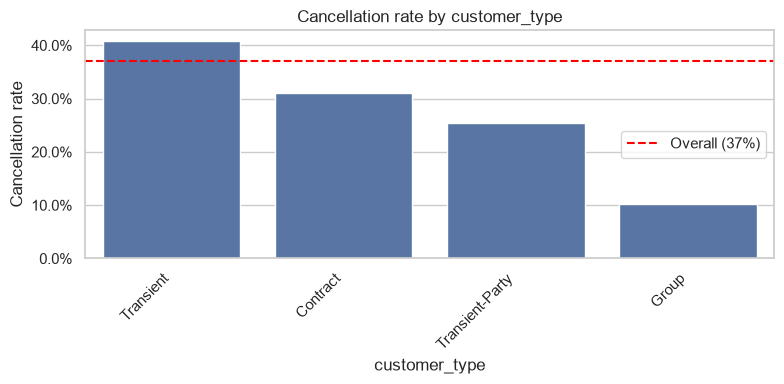

     customer_type      rate      n
2        Transient  0.407463  89613
0         Contract  0.309617   4076
3  Transient-Party  0.254299  25124
1            Group  0.102253    577 



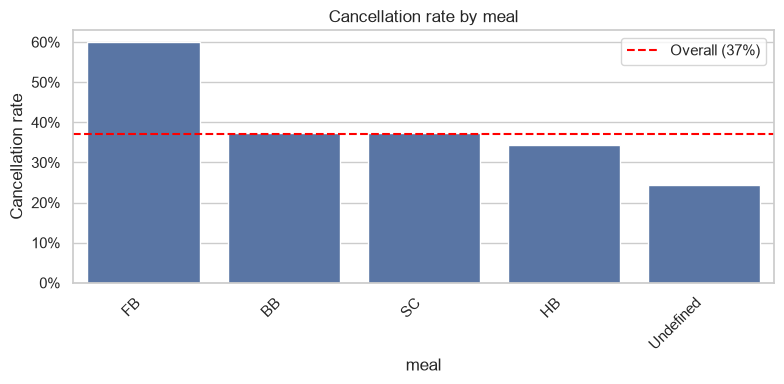

        meal      rate      n
1         FB  0.598997    798
0         BB  0.373849  92310
3         SC  0.372394  10650
2         HB  0.344603  14463
4  Undefined  0.244654   1169 



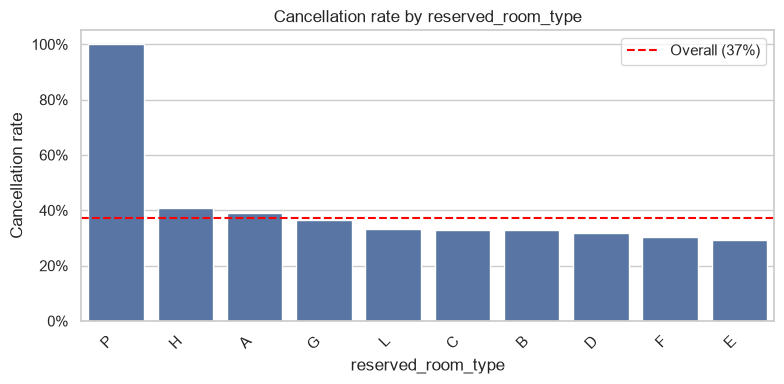

  reserved_room_type      rate      n
9                  P  1.000000     12
7                  H  0.407654    601
0                  A  0.391074  85994
6                  G  0.364374   2094
8                  L  0.333333      6
2                  C  0.330472    932
1                  B  0.329159   1118
3                  D  0.317796  19201
5                  F  0.303763   2897
4                  E  0.292884   6535 



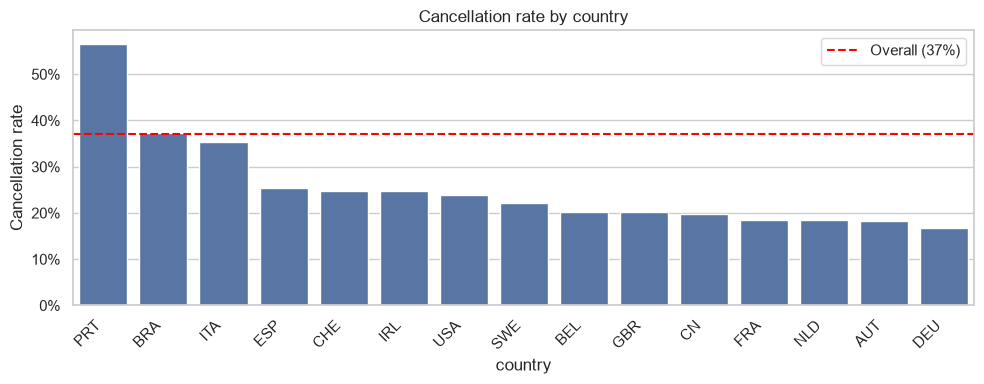

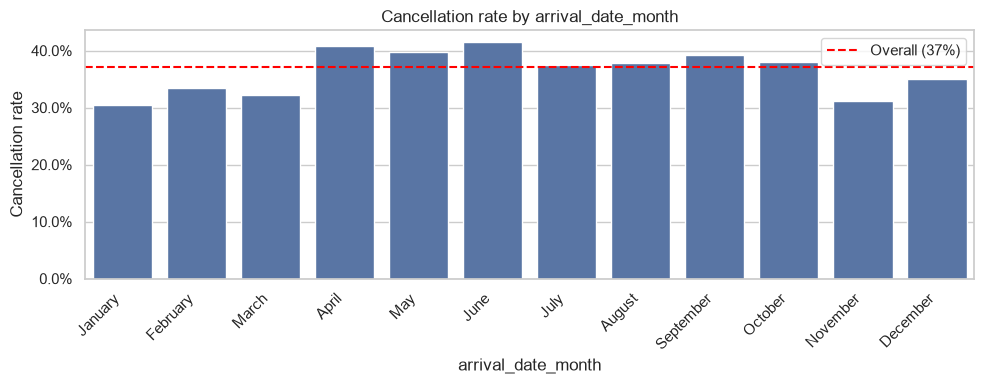

,arrival_date_month,rate,n
0,January,0.304773,5929
1,February,0.334160,8068
2,March,0.321523,9794
3,April,0.407972,11089
4,May,0.396658,11791
5,June,0.414572,10939
6,July,0.374536,12661
7,August,0.377531,13877
8,September,0.391702,10508
9,October,0.380466,11160


In [12]:
#Categorical drivers
for col in ["hotel", "deposit_type", "market_segment", "distribution_channel",
            "customer_type", "meal", "reserved_room_type"]:
    print(cancel_rate_by(col, name=f"02_{col}"), "\n")

# Country (top 15 by volume) and arrival month
cancel_rate_by("country", top=15, figsize=(10, 4), name="02_country")
cancel_rate_by("arrival_date_month", figsize=(10, 4), name="02_month")


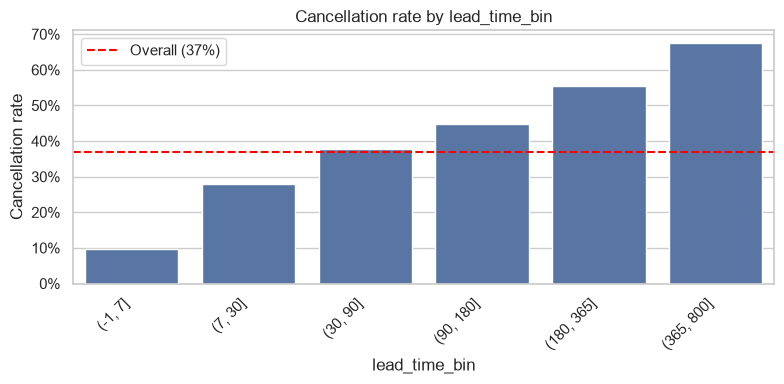

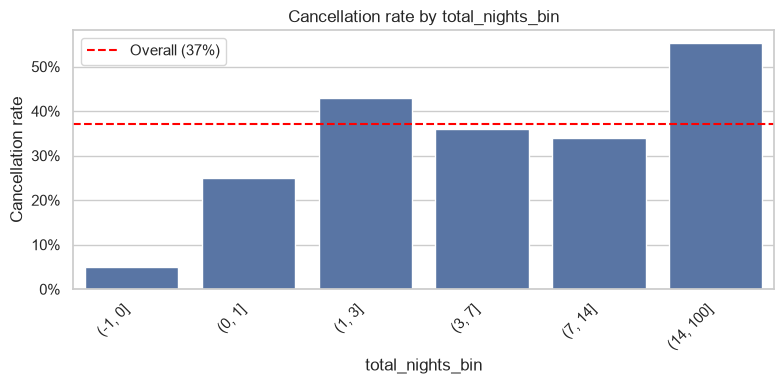

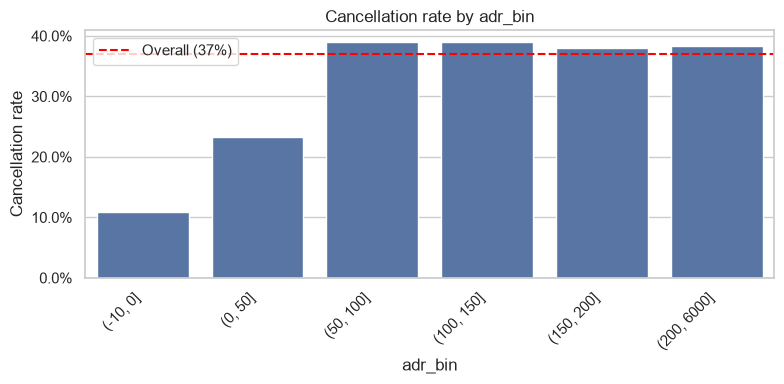

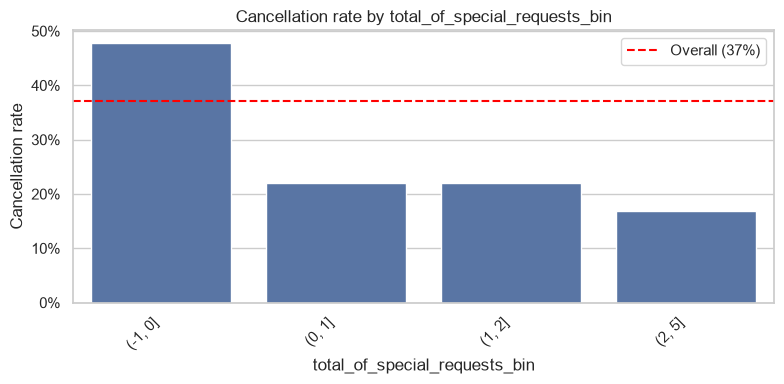

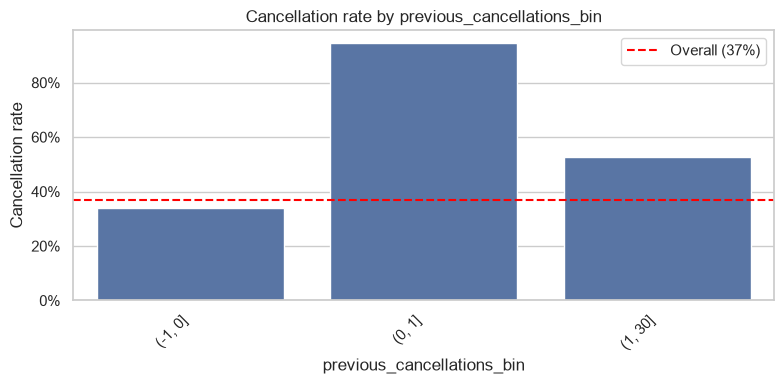

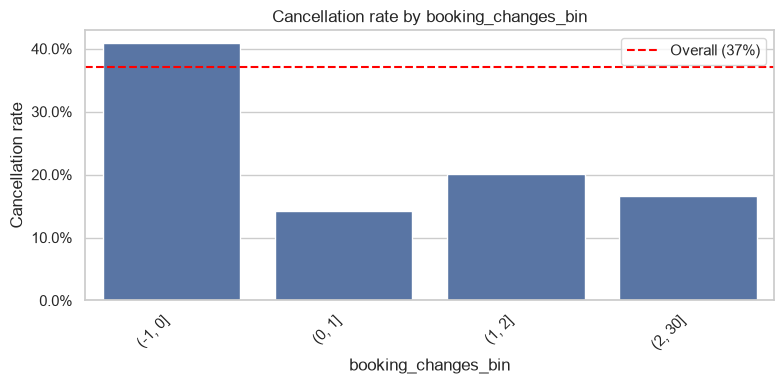

In [13]:
#Numeric drivers: bin then compare cancellation rates
bins = {
    "lead_time": [-1, 7, 30, 90, 180, 365, 800],
    "total_nights": [-1, 0, 1, 3, 7, 14, 100],
    "adr": [-10, 0, 50, 100, 150, 200, 6000],
    "total_of_special_requests": [-1, 0, 1, 2, 5],
    "previous_cancellations": [-1, 0, 1, 30],
    "booking_changes": [-1, 0, 1, 2, 30],
}
for col, b in bins.items():
    d[f"{col}_bin"] = pd.cut(d[col], bins=b)
    cancel_rate_by(f"{col}_bin", name=f"03_{col}")

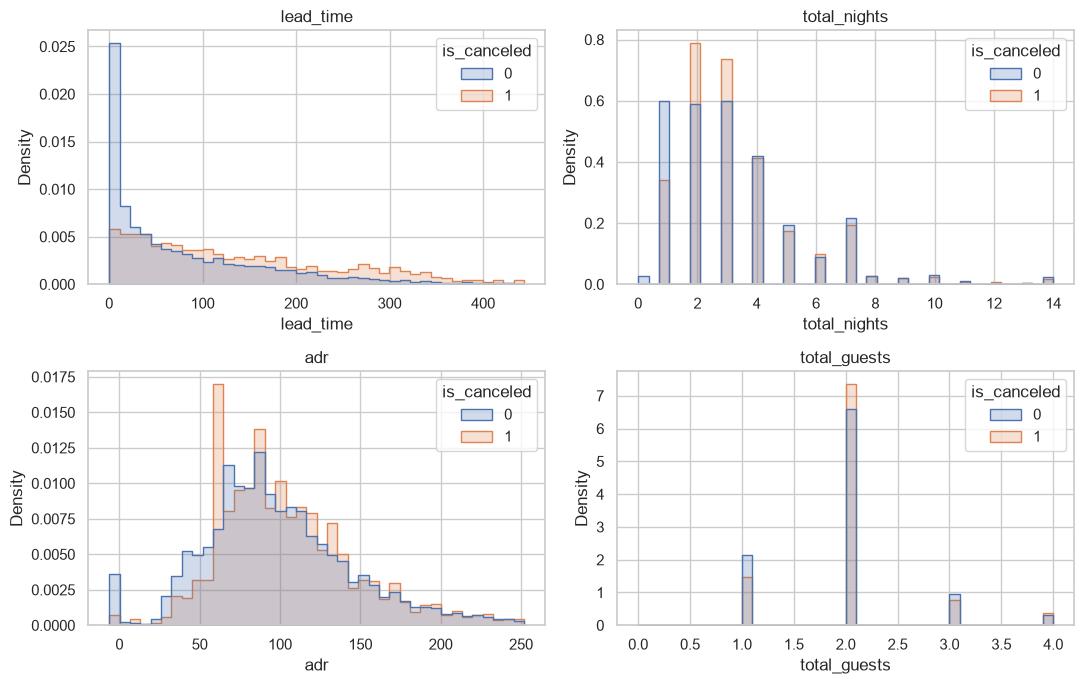

In [14]:
#Distributions: canceled vs not canceled
num_cols = ["lead_time", "total_nights", "adr", "total_guests"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), num_cols):
    clip = d[col].quantile(0.99)           # trim extreme outliers for readability
    sns.histplot(data=d[d[col] <= clip], x=col, hue=TARGET, bins=40,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(col)
save("04_distributions")

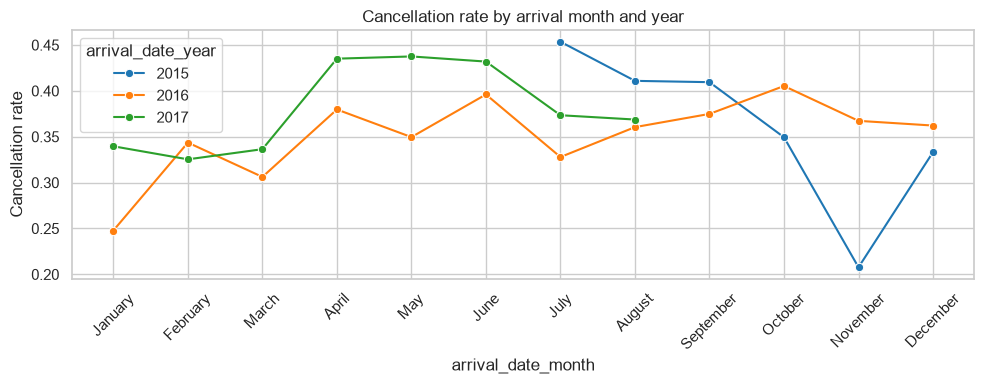

In [15]:
#Cancellation over time (by arrival month and year)
t = (d.groupby(["arrival_date_year", "arrival_date_month"], observed=True)[TARGET]
       .mean().reset_index())
plt.figure(figsize=(10, 4))
sns.lineplot(data=t, x="arrival_date_month", y=TARGET,
             hue="arrival_date_year", marker="o", palette="tab10")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45)
plt.title("Cancellation rate by arrival month and year")
save("05_time_trend")

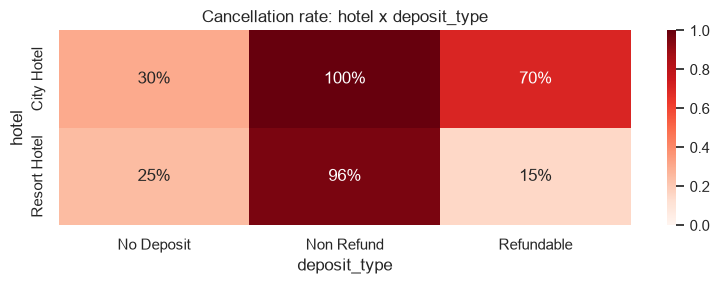

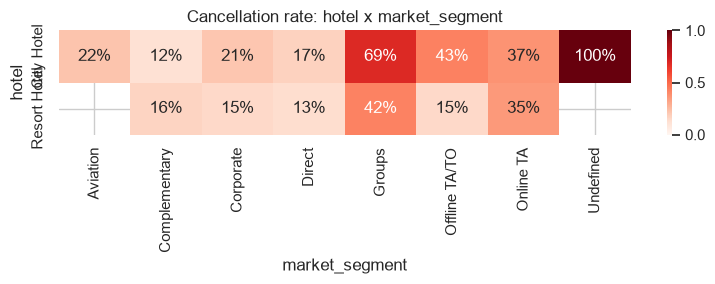

In [16]:
#Two-way view: hotel x deposit type, hotel x market segment
for a, b in [("hotel", "deposit_type"), ("hotel", "market_segment")]:
    pivot = d.pivot_table(index=a, columns=b, values=TARGET, aggfunc="mean")
    plt.figure(figsize=(8, 3))
    sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=1)
    plt.title(f"Cancellation rate: {a} x {b}")
    save(f"06_{a}_x_{b}")

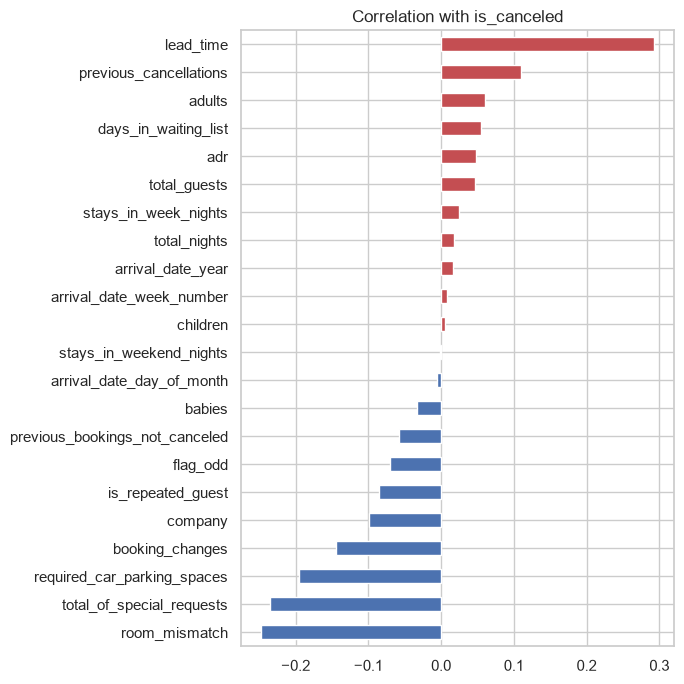

room_mismatch                    -0.248
total_of_special_requests        -0.235
required_car_parking_spaces      -0.195
booking_changes                  -0.144
company                          -0.099
is_repeated_guest                -0.085
flag_odd                         -0.071
previous_bookings_not_canceled   -0.057
babies                           -0.032
arrival_date_day_of_month        -0.006
stays_in_weekend_nights          -0.002
children                          0.005
arrival_date_week_number          0.008
arrival_date_year                 0.017
total_nights                      0.018
stays_in_week_nights              0.025
total_guests                      0.047
adr                               0.048
days_in_waiting_list              0.054
adults                            0.060
previous_cancellations            0.110
lead_time                         0.293
Name: is_canceled, dtype: float64


In [17]:
#Correlation with the target (numeric features)
numeric = d.select_dtypes(include=[np.number]).drop(columns=[c for c in d.columns if c.endswith("_bin")],
                                                    errors="ignore")
corr = numeric.corr()[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(7, 7))
corr.plot(kind="barh", color=np.where(corr > 0, "#C44E52", "#4C72B0"))
plt.title("Correlation with is_canceled")
save("07_correlations")
print(corr.round(3))

In [18]:
#Effect of duplicates and odd records on the cancellation rate
print("Rate, all rows:            ", f"{d[TARGET].mean():.3f}")
print("Rate, drop duplicates:     ", f"{d.drop_duplicates()[TARGET].mean():.3f}")
print("Rate, drop odd records:    ", f"{d[d['flag_odd'] == 0][TARGET].mean():.3f}")

Rate, all rows:             0.370
Rate, drop duplicates:      0.273
Rate, drop odd records:     0.375


In [20]:
#Summary table of key findings (copy into your report)
summary = {
    "Overall rate": rate,
    "City Hotel": d.loc[d.hotel == "City Hotel", TARGET].mean(),
    "Resort Hotel": d.loc[d.hotel == "Resort Hotel", TARGET].mean(),
    "Non Refund deposit": d.loc[d.deposit_type == "Non Refund", TARGET].mean(),
    "Lead time <= 7 days": d.loc[d.lead_time <= 7, TARGET].mean(),
    "Lead time > 365 days": d.loc[d.lead_time > 365, TARGET].mean(),
    "No special requests": d.loc[d.total_of_special_requests == 0, TARGET].mean(),
    "Has previous cancellation": d.loc[d.previous_cancellations > 0, TARGET].mean(),
    "Room mismatch (assigned != reserved)": d.loc[d.room_mismatch == 1, TARGET].mean(),
}
print(pd.Series(summary).map("{:.1%}".format))

Overall rate                            37.0%
City Hotel                              41.7%
Resort Hotel                            27.8%
Non Refund deposit                      99.4%
Lead time <= 7 days                      9.6%
Lead time > 365 days                    67.7%
No special requests                     47.7%
Has previous cancellation               91.6%
Room mismatch (assigned != reserved)     5.4%
dtype: str


# Data pre-processing

In [22]:
#Modeling choices we should agree on (and justify in the report) ---
DROP_DUPLICATES = True       # identical rows in both train and test inflate KNN scores
USE_POST_BOOKING = False     # False = only information known when the booking is made
TEST_SIZE = 0.20


In [26]:
#Load and clean
df = pd.read_csv("/Users/kingsice/Desktop/hotel_bookings.csv")

# Leakage: these reveal the outcome directly
df = df.drop(columns=["reservation_status", "reservation_status_date"])

if DROP_DUPLICATES:
    before = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Dropped {before - len(df):,} duplicate rows -> {len(df):,} remain")

# Remove clearly invalid records (zero guests, zero nights, impossible ADR)
guests = df["adults"] + df["children"].fillna(0) + df["babies"]
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
bad = (guests == 0) | (nights == 0) | (df["adr"] <= 0) | (df["adr"] > 1000)
print(f"Removing {bad.sum():,} invalid records")
df = df[~bad].reset_index(drop=True)

Dropped 32,252 duplicate rows -> 87,138 remain
Removing 1,811 invalid records


In [27]:
#Feature engineering
df["children"] = df["children"].fillna(0)
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)

# Country has ~170 levels: keep the 10 most common, group the rest.
# (Top countries are chosen from the data; with a very strict workflow you would
# compute this on the training set only. Impact here is negligible.)
top_countries = df["country"].value_counts().head(10).index
df["country_grp"] = np.where(df["country"].isin(top_countries), df["country"], "Other")

numeric_features = [
    "lead_time", "arrival_date_week_number", "total_nights", "total_guests",
    "adr", "total_of_special_requests", "previous_cancellations",
    "previous_bookings_not_canceled", "is_repeated_guest",
    "has_agent", "has_company",
]
categorical_features = [
    "hotel", "arrival_date_month", "meal", "market_segment",
    "distribution_channel", "deposit_type", "customer_type",
    "reserved_room_type", "country_grp",
]

if USE_POST_BOOKING:
    # Finalized after booking or at check-in; including them boosts accuracy
    # but is not realistic for predicting at booking time.
    df["room_mismatch"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)
    numeric_features += ["booking_changes", "days_in_waiting_list",
                         "required_car_parking_spaces", "room_mismatch"]

X = df[numeric_features + categorical_features]
y = df[TARGET]
print("Feature matrix:", X.shape, "| cancellation rate:", round(y.mean(), 3))

Feature matrix: (85327, 20) | cancellation rate: 0.276


# Data split

In [29]:
#Train / test split (stratified so both sets keep the same cancel rate)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=42)

print(f"Train: {X_train.shape[0]:,} rows ({y_train.mean():.3f} canceled)")
print(f"Test:  {X_test.shape[0]:,} rows ({y_test.mean():.3f} canceled)")

Train: 68,261 rows (0.276 canceled)
Test:  17,066 rows (0.276 canceled)


In [30]:
#Preprocessing + KNN pipeline
# KNN is distance-based, so numeric features MUST be scaled, and categoricals
# one-hot encoded. Wrapping everything in a Pipeline means scaling is fit on
# the training folds only (no leakage into validation or test data).
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

knn_pipe = Pipeline([
    ("prep", preprocess),
    ("knn", KNeighborsClassifier(n_jobs=-1)),
])


In [33]:
#Tune k (and weighting) with cross-validation on the TRAINING set
# KNN is slow on large data (every prediction scans all training rows), so we
# tune on a random subsample of the training set, then refit the best setting
# on the FULL training set. Set TUNE_SAMPLE = None to tune on everything
# (much slower; expect many minutes).
TUNE_SAMPLE = 20000
CV_FOLDS = 3

param_grid = {
    "knn__n_neighbors": [5, 11, 21, 41, 81],
    "knn__weights": ["uniform", "distance"],
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

if TUNE_SAMPLE and TUNE_SAMPLE < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNE_SAMPLE,
        stratify=y_train, random_state=42)
else:
    X_tune, y_tune = X_train, y_train

grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="roc_auc",
                    n_jobs=1, refit=False, verbose=1)  # KNN already uses all cores
grid.fit(X_tune, y_tune)

best_params = grid.best_params_
print("\nBest params:", best_params)
print(f"Best CV AUC (on tuning sample): {grid.best_score_:.4f}")

# Refit the best configuration on the full training set
best = knn_pipe.set_params(**best_params).fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best params: {'knn__n_neighbors': 41, 'knn__weights': 'distance'}
Best CV AUC (on tuning sample): 0.8066


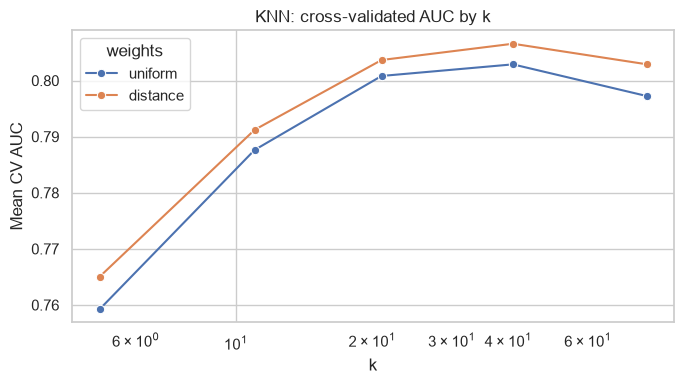

In [34]:
#Plot: validation AUC vs k
res = pd.DataFrame(grid.cv_results_)
res["k"] = res["param_knn__n_neighbors"].astype(int)
res["weights"] = res["param_knn__weights"]

plt.figure(figsize=(7, 4))
sns.lineplot(data=res, x="k", y="mean_test_score", hue="weights", marker="o")
plt.xscale("log")
plt.ylabel("Mean CV AUC")
plt.title("KNN: cross-validated AUC by k")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_k_tuning.png", dpi=150)
plt.show()

Test AUC: 0.8326

              precision    recall  f1-score   support

Not canceled      0.823     0.925     0.871     12350
    Canceled      0.710     0.480     0.573      4716

    accuracy                          0.802     17066
   macro avg      0.767     0.703     0.722     17066
weighted avg      0.792     0.802     0.789     17066



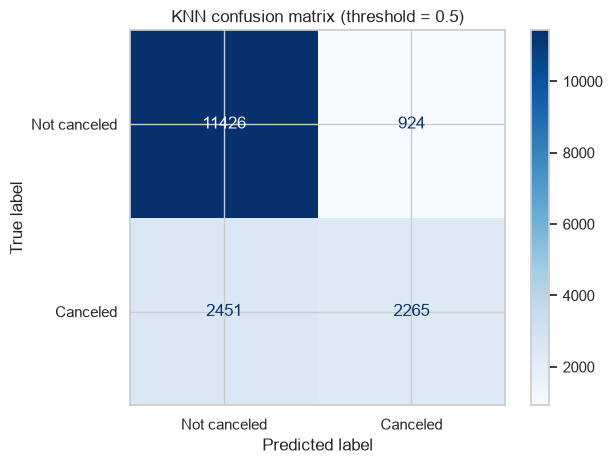

In [35]:
#Evaluate the best model on the held-out TEST set
proba = best.predict_proba(X_test)[:, 1]
pred_default = (proba >= 0.5).astype(int)

print(f"Test AUC: {roc_auc_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred_default,
                            target_names=["Not canceled", "Canceled"], digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_default, display_labels=["Not canceled", "Canceled"], cmap="Blues")
plt.title("KNN confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_confusion_matrix.png", dpi=150)
plt.show()

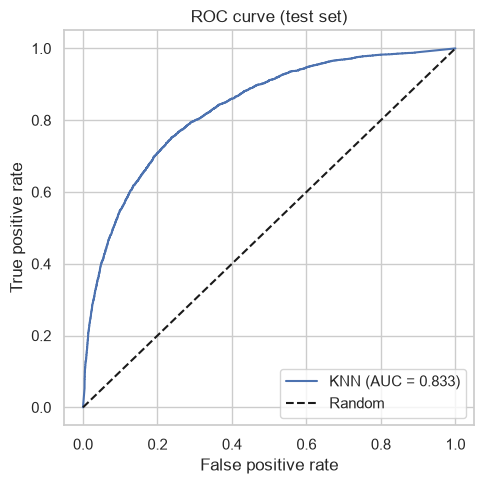

In [36]:
#ROC curve
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (test set)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_roc.png", dpi=150)
plt.show()

In [37]:
#Threshold exploration (recall vs precision trade-off)
rows = []
for t in np.arange(0.2, 0.8, 0.1):
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": round(t, 1),
                 "precision": tp / (tp + fp) if (tp + fp) else np.nan,
                 "recall": tp / (tp + fn),
                 "flagged_%": p.mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 threshold  precision  recall  flagged_%
       0.2      0.439   0.877      0.552
       0.3      0.541   0.756      0.386
       0.4      0.629   0.622      0.273
       0.5      0.714   0.480      0.186
       0.6      0.782   0.338      0.119
       0.7      0.845   0.211      0.069
       0.8      0.877   0.119      0.038
